# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
data=pd.read_csv("SiComplete-2023-04-13-BiatriSrv-v2.3-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=data.rename(columns={"##JobID": "JobID"})
data.describe(include="all")
datafull=data
data.dtypes


JobID                           float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64


# Database filtering

In [4]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=24]
data

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,...,0.006785,3.398284e-03,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.010887,4.497317e-03,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.012325,-7.674286e-02,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.006391,-3.751058e-02,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.014642,6.658762e-03,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2904,315003.0,20230403.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,4.000000e+09,1.884956,0.0,...,0.400703,-3.230202e-04,-6.029316e+14,1.649744e+28,3.311494e+41,3.312427e+41,1.0,0.0,5290.0,4117.988325
2905,315000.0,20230223.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,1.600000e+09,1.884956,0.0,...,0.017268,4.356615e-07,7.480073e+13,7.001876e+26,1.402931e+40,1.405867e+40,1.0,0.0,5290.0,4117.988325
2906,315001.0,20230327.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,1.884956,0.0,...,0.046539,-1.026761e-06,2.956668e+13,1.869398e+27,3.747973e+40,3.753459e+40,1.0,0.0,5290.0,4117.988325
2907,315002.0,20230328.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,1.884956,0.0,...,0.189183,1.558303e-04,-1.829517e+14,7.465903e+27,1.498541e+41,1.499036e+41,1.0,0.0,5290.0,4117.988325


In [5]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,...,0.006785,3.398284e-03,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.010887,4.497317e-03,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.012325,-7.674286e-02,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.006391,-3.751058e-02,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.014642,6.658762e-03,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2904,315003.0,20230403.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,4.000000e+09,1.884956,0.0,...,0.400703,-3.230202e-04,-6.029316e+14,1.649744e+28,3.311494e+41,3.312427e+41,1.0,0.0,5290.0,4117.988325
2905,315000.0,20230223.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,1.600000e+09,1.884956,0.0,...,0.017268,4.356615e-07,7.480073e+13,7.001876e+26,1.402931e+40,1.405867e+40,1.0,0.0,5290.0,4117.988325
2906,315001.0,20230327.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,1.884956,0.0,...,0.046539,-1.026761e-06,2.956668e+13,1.869398e+27,3.747973e+40,3.753459e+40,1.0,0.0,5290.0,4117.988325
2907,315002.0,20230328.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,1.884956,0.0,...,0.189183,1.558303e-04,-1.829517e+14,7.465903e+27,1.498541e+41,1.499036e+41,1.0,0.0,5290.0,4117.988325


In [6]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [7]:
datafull

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637.0,20180601.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,...,8.262708e-04,0.000004,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1468,8715191.0,20190625.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,...,1.952543e-02,-0.000109,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1523,8918119.0,20190708.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,...,4.079272e-02,-0.000297,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
312,5027620.0,20180524.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,...,6.555565e-02,0.000637,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1413,8918121.0,20190709.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,...,1.123667e-01,-0.001849,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1403,10050046.0,20191101.0,24.0,0.434637,0.25,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,...,3.690789e-07,0.000226,4.772547e+13,3.844612e+27,2.465914e+35,1.922306e+41,3.0,2.0,3750.0,1392.217365
1738,17608855.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,...,2.562692e-06,0.000335,9.126526e+13,5.590327e+24,7.342516e+34,9.317212e+37,3.0,2.0,7750.0,3363.042231
1735,17638129.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,...,2.733345e-05,0.000839,7.494762e+13,1.337371e+25,1.286704e+37,2.228952e+38,3.0,2.0,7625.0,3363.042231
1711,17608858.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,...,4.830202e-04,0.001603,-5.717359e+12,3.822728e+25,2.664830e+38,6.371213e+38,3.0,2.0,7500.0,3363.042231


In [8]:
set(datafull[datafull.PolarizationAngle!=0].lambda1)

{1.0625e-06, 2.656e-06}

# $N_{exc}(\phi)$

## Role of intensity

In [9]:
from scipy.constants import pi
from octopus_slabs.Libs.libPlotting import PulseTypeID
# print(PulseTypeID['SinSquared'])
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda1-800e-9)<1e-9]
# datatmp=datatmp[np.fabs(datatmp.lambda1-895e-9)<1e-9] #800 nm Astrella renormalized to TB09
datatmp=datatmp[np.fabs(datatmp.lambda1-1.0625e-06)<1e-9] #800 nm Astrella renormalized to LDA
# datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.Efield1==6.07E9]
# datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==PulseTypeID['SinSquared']]
# datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp
data025 = datatmp[datatmp.TimeStep==0.25]
data020 = datatmp[datatmp.TimeStep==0.2]
# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]
data3_1Vnm=datatmp[datatmp.Efield1==1E9]
data3_6overIndexVnm=datatmp[datatmp.Efield1==1.73E9]
data3_6Vnm=datatmp[datatmp.Efield1==6.07E9]
data3_2Vnm=datatmp[datatmp.Efield1==2000000000.0]
data3_3Vnm=datatmp[datatmp.Efield1==3000000000]
data3_4Vnm=datatmp[datatmp.Efield1==4000000000]

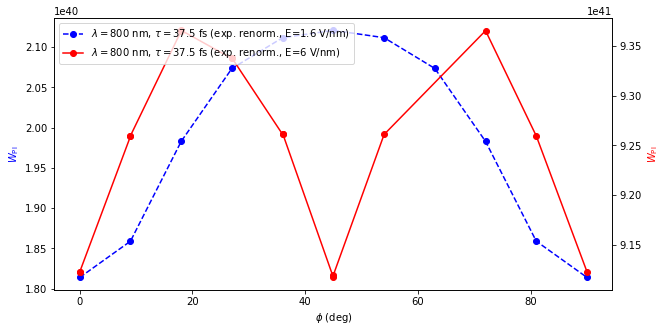

In [10]:
plot1=[]
fig = plt.figure(figsize=(10,5))
ax1 = plt.subplot(111)
plt.xlabel(r"$\phi$ (deg)")
# plot_field, = ax1.plot(180./pi*data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-ob", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1 V/nm)")
# plot1 += [plot_field]
plot_field, = ax1.plot(180./pi*data3_6overIndexVnm.PolarizationAngle, data3_6overIndexVnm.Wpi, "--ob", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1.6 V/nm)")
plot1 += [plot_field]
ax1.set_ylabel(r"$W_{\mathrm{PI}}$")
ax1.yaxis.label.set_color("blue")

ax12 = ax1.twinx()
plot_field, = ax12.plot(180./pi*data3_6Vnm.PolarizationAngle, data3_6Vnm.Wpi, "-or", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=6 V/nm)")
plot1 += [plot_field]
ax12.set_ylabel(r"$W_{\mathrm{PI}}$")
ax12.yaxis.label.set_color("red")

labels1 = [l.get_label() for l in plot1]
plt.legend(plot1, labels1, loc=2)
plt.show()

In [11]:
datatmp
# datatmp.to_csv('Si-k40-Nexc-Orientation.csv')

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2579,245784.0,20221015.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.000000e+09,0.000000,0.0,...,0.001481,2.448829e-06,-2.222797e+14,6.238033e+25,1.241066e+39,1.252499e+39,1.0,0.0,5290.0,4117.988325
2846,249930.0,20221030.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.000000e+09,0.157080,0.0,...,0.001522,2.809654e-06,-2.194236e+14,6.596159e+25,1.313132e+39,1.324405e+39,1.0,0.0,5290.0,4117.988325
2849,249931.0,20221030.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.000000e+09,0.314159,0.0,...,0.001711,2.328352e-06,-2.107720e+14,7.483224e+25,1.490696e+39,1.502514e+39,1.0,0.0,5290.0,4117.988325
2842,249932.0,20221031.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.000000e+09,0.471239,0.0,...,0.001980,9.960863e-07,-1.965263e+14,8.478426e+25,1.689647e+39,1.702335e+39,1.0,0.0,5290.0,4117.988325
2838,245788.0,20221031.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.000000e+09,0.628319,0.0,...,0.002171,3.436095e-07,-3.904771e+13,9.192217e+25,1.832824e+39,1.845653e+39,1.0,0.0,4625.0,4117.988325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2641,245624.0,20221015.0,24.0,0.434637,0.20,0.000001,4.980469e-14,6.070000e+09,0.785398,0.0,...,1.059811,1.667216e-02,-2.432550e+15,4.541677e+28,9.119693e+41,9.118974e+41,1.0,0.0,4500.0,4117.988325
2861,250974.0,20221111.0,24.0,0.434637,0.25,0.000001,4.980469e-14,6.070000e+09,0.942478,0.0,...,1.081091,1.017993e-02,2.724634e+15,4.613463e+28,9.260974e+41,9.263109e+41,1.0,0.0,4375.0,4117.988325
2869,253866.0,20221119.0,24.0,0.434637,0.25,0.000001,4.980469e-14,6.070000e+09,1.256637,0.0,...,1.085488,-3.689963e-02,1.530138e+15,4.665260e+28,9.365366e+41,9.367110e+41,1.0,0.0,5000.0,4117.988325
2859,251891.0,20221118.0,24.0,0.434637,0.25,0.000001,4.980469e-14,6.070000e+09,1.413717,0.0,...,1.075338,4.346992e-02,6.626023e+14,4.612765e+28,9.259487e+41,9.261708e+41,1.0,0.0,5290.0,4117.988325


## Plotting result for 800 nm, 37.5 fs

### Checking effect of timestep

In [12]:
data2=data025

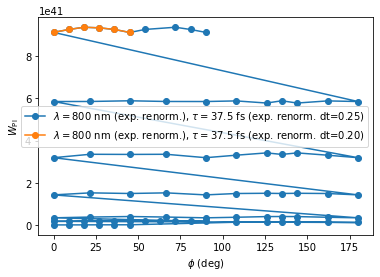

In [13]:
from scipy.constants import pi
plt.figure()
plt.subplot(polar=False)
plt.plot(180./pi*data025.PolarizationAngle, data025.Wpi, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm. dt=0.25)")
plt.plot(180./pi*data020.PolarizationAngle, data020.Wpi, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm. dt=0.20)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

### After pulse vs end of simulation

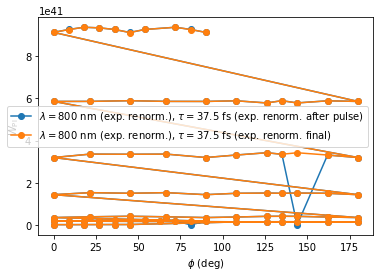

In [14]:
from scipy.constants import pi
plt.figure()
plt.subplot(polar=False)
plt.plot(180./pi*data2.PolarizationAngle, data2.Wpi_afterpulse, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm. after pulse)")
plt.plot(180./pi*data2.PolarizationAngle, data2.Wpi, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm. final)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

In [15]:
name_lambda1=np.array(data2.lambda1*1E9)[0]
name_Efield1=np.array(data2.Efield1*1E-9)[0]
name_tau1   =np.array(data2.tau1*1E15)[0]
print(name_lambda1, name_Efield1, name_tau1)

1062.5 1.0 49.8046875


### Polar response graph

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


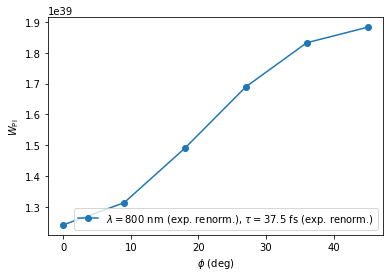

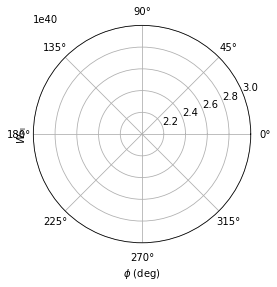

In [16]:
plt.figure()
plt.subplot(polar=False)
plt.plot(data3_1Vnm.PolarizationAngle*180./np.pi, data3_1Vnm.Wpi, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.savefig("AngleVsWpi-"+str(name_lambda1)+"-tau"+str(name_tau1)+"-field"+str(name_Efield1)+".eps")
plt.show()

plt.figure()
plt.subplot(polar=True)
plt.plot(data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-")
plt.plot(data3_1Vnm.PolarizationAngle+2*45./180.*np.pi, data3_1Vnm.Wpi, "-")
plt.plot(4*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-")
plt.plot(data3_1Vnm.PolarizationAngle+4*45./180.*np.pi, data3_1Vnm.Wpi, "-")
plt.plot(6*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-")
plt.plot(data3_1Vnm.PolarizationAngle+6*45./180.*np.pi, data3_1Vnm.Wpi, "-")
plt.plot(8*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Wpi, "-")
plt.ylim([2E40,3E40])

# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.legend(loc="best")
plt.savefig("AngleVsWpiPolar-lambda"+str(name_lambda1)+"nm-tau"+str(name_tau1)+"fs-field"+str(name_Efield1)+"VperNm.eps")
plt.show()


In [17]:
!pwd

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Energy($\phi$)

In [18]:
print(data3_1Vnm.JobID), print(data3_1Vnm.PolarizationAngle)
print(data3_1Vnm.Energy_eV), print(data3_1Vnm.Energy_afterpulse_eV)

2579    245784.0
2846    249930.0
2849    249931.0
2842    249932.0
2838    245788.0
2640    245789.0
Name: JobID, dtype: float64
2579    0.000000
2846    0.157080
2849    0.314159
2842    0.471239
2838    0.628319
2640    0.785398
Name: PolarizationAngle, dtype: float64
2579    0.009260
2846    0.009821
2849    0.011198
2842    0.012713
2838    0.013804
2640    0.014196
Name: Energy_eV, dtype: float64
2579    0.009260
2846    0.009821
2849    0.011198
2842    0.012713
2838    0.013804
2640    0.014196
Name: Energy_afterpulse_eV, dtype: float64


(None, None)

In [19]:
print(data3_6Vnm.JobID), print(data3_6Vnm.PolarizationAngle)
print(data3_6Vnm.Energy_eV), print(data3_6Vnm.Energy_afterpulse_eV)

2577    239316.0
2578    245619.0
2844    249085.0
2845    245620.0
2848    243837.0
2850    245306.0
2840    239319.0
2841    245307.0
2836    242533.0
2837    245308.0
2639    239321.0
2641    245624.0
2861    250974.0
2869    253866.0
2859    251891.0
2864    250809.0
Name: JobID, dtype: float64
2577    0.000000
2578    0.000000
2844    0.157080
2845    0.157080
2848    0.314159
2850    0.314159
2840    0.471239
2841    0.471239
2836    0.628319
2837    0.628319
2639    0.785398
2641    0.785398
2861    0.942478
2869    1.256637
2859    1.413717
2864    1.570796
Name: PolarizationAngle, dtype: float64
2577    25.714766
2578    25.714399
2844    26.188237
2845    26.187962
2848    26.264218
2850    26.264096
2840    26.265347
2841    26.265511
2836    26.097580
2837    26.098085
2639    25.752248
2641    25.752934
2861    26.097582
2869    26.264219
2859    26.188236
2864    25.714765
Name: Energy_eV, dtype: float64
2577    25.714770
2578    25.714399
2844    26.188238
2845    26.187

(None, None)

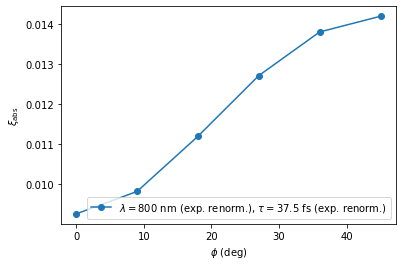

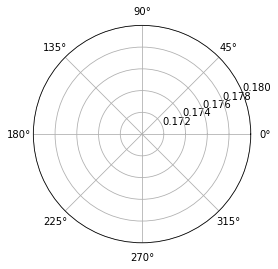

In [20]:
plt.figure()
plt.subplot(polar=False)
plt.plot(data3_1Vnm.PolarizationAngle*180./pi, data3_1Vnm.Energy_eV, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$\xi_{\mathrm{abs}}$")
plt.legend(loc="best")
plt.show()

plt.figure()
plt.subplot(polar=True)
plt.plot(data3_1Vnm.PolarizationAngle+0*45./180.*np.pi, data3_1Vnm.Energy_eV, "-", label=r"$\lambda=8$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Energy_eV, "-")
plt.plot(data3_1Vnm.PolarizationAngle+2*45./180.*np.pi, data3_1Vnm.Energy_eV, "-")
plt.plot(4*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Energy_eV, "-")
plt.plot(data3_1Vnm.PolarizationAngle+4*45./180.*np.pi, data3_1Vnm.Energy_eV, "-")
plt.plot(6*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Energy_eV, "-")
plt.plot(data3_1Vnm.PolarizationAngle+6*45./180.*np.pi, data3_1Vnm.Energy_eV, "-")
plt.plot(8*45./180.*np.pi-data3_1Vnm.PolarizationAngle, data3_1Vnm.Energy_eV, "-")
plt.ylim([0.17,0.18])
plt.show()

## Strong field

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:59: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7fdfd36e97f0> has a label of '_line0' which cannot be automatically added to the legend.
/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:59: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7fdfd36e9e80> has a label of '_line1' which cannot be automatically added to the legend.
/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:59: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7fdfd36fb518> has a label of '_line2' which cannot be automatically added to the legend.
/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:59: UserWarning: The handle <matplotlib.lines.Line2D object at 0x7fdfd36fbba8> has a label of '_line3' which cannot be automatically added to 

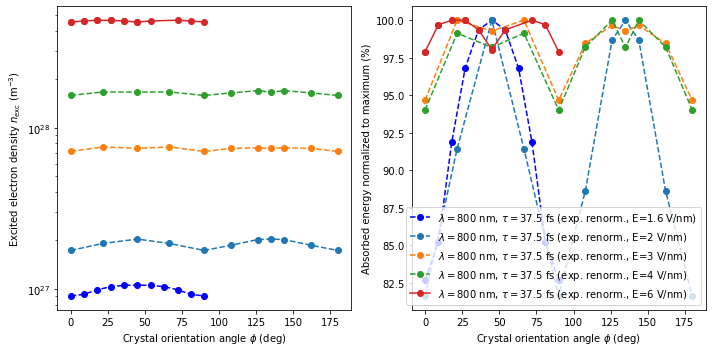

In [21]:
plot1=[]
fig = plt.figure(figsize=(10,5))
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
# ax3 = plt.subplot(223)
# ax4 = plt.subplot(224)
ax1.set_xlabel(r"Crystal orientation angle $\phi$ (deg)")
ax2.set_xlabel(r"Crystal orientation angle $\phi$ (deg)")
# ax3.set_xlabel(r"Crystal orientation angle $\phi$ (deg)")
# ax4.set_xlabel(r"Crystal orientation angle $\phi$ (deg)")
# plot_field, = ax1.plot(180./pi*data3_1Vnm.PolarizationAngle, data3_1Vnm.Energy_eV, "-ob", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1 V/nm)")
# plot1 += [plot_field]

ax1.set_ylabel(r"Excited electron density $n_{\mathrm{exc}}$ (m$^{-3}$)")
ax2.set_ylabel(r"Absorbed energy normalized to maximum (%)")
# ax2.yaxis.label.set_color("blue")

# plot_field, = ax1.plot(180./pi*data3_6overIndexVnm.PolarizationAngle, data3_6overIndexVnm.Energy_eV, "--ob", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1.6 V/nm)")
# plot1 += [plot_field]

plot_field, = ax1.plot(180./pi*data3_6overIndexVnm.PolarizationAngle, data3_6overIndexVnm.NeFinal, "--ob", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1.6 V/nm)")
plot1 += [plot_field]
plot_field, = ax2.plot(180./pi*data3_6overIndexVnm.PolarizationAngle, 100*data3_6overIndexVnm.Energy_eV/np.max(data3_6overIndexVnm.Energy_eV), "--ob") #, label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=1.6 V/nm)")
plot1 += [plot_field]

# plot_field, = ax1.plot(180./pi*data3_2Vnm.PolarizationAngle, data3_2Vnm.Energy_eV, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=2 V/nm)")
# plot1 += [plot_field]

plot_field, = ax1.plot(180./pi*data3_2Vnm.PolarizationAngle, data3_2Vnm.NeFinal, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=2 V/nm)")
plot1 += [plot_field]
plot_field, = ax2.plot(180./pi*data3_2Vnm.PolarizationAngle, 100*data3_2Vnm.Energy_eV/np.max(data3_2Vnm.Energy_eV), "--o") #, label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=2 V/nm)")
plot1 += [plot_field]

# plot_field, = ax1.plot(180./pi*data3_3Vnm.PolarizationAngle, data3_3Vnm.Energy_eV, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=3 V/nm)")
# plot1 += [plot_field]

plot_field, = ax1.plot(180./pi*data3_3Vnm.PolarizationAngle, data3_3Vnm.NeFinal, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=3 V/nm)")
plot1 += [plot_field]
plot_field, = ax2.plot(180./pi*data3_3Vnm.PolarizationAngle, 100*data3_3Vnm.Energy_eV/np.max(data3_3Vnm.Energy_eV), "--o") #, label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=3 V/nm)")
plot1 += [plot_field]

# plot_field, = ax1.plot(180./pi*data3_4Vnm.PolarizationAngle, data3_4Vnm.Energy_eV, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=4 V/nm)")
# plot1 += [plot_field]

plot_field, = ax1.plot(180./pi*data3_4Vnm.PolarizationAngle, data3_4Vnm.NeFinal, "--o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=4 V/nm)")
plot1 += [plot_field]
plot_field, = ax2.plot(180./pi*data3_4Vnm.PolarizationAngle, 100*data3_4Vnm.Energy_eV/np.max(data3_4Vnm.Energy_eV), "--o") #, label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=4 V/nm)")
plot1 += [plot_field]

# ax12 = ax1.twinx()
plot_field, = ax1.plot(180./pi*data3_6Vnm.PolarizationAngle, data3_6Vnm.NeFinal, "-o", label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=6 V/nm)")
plot1 += [plot_field]
plot_field, = ax2.plot(180./pi*data3_6Vnm.PolarizationAngle, 100*data3_6Vnm.Energy_eV/np.max(data3_6Vnm.Energy_eV), "-o") #, label=r"$\lambda=800$ nm, $\tau=$37.5 fs (exp. renorm., E=6 V/nm)")
plot1 += [plot_field]

# ax12.yaxis.label.set_color("red")
ax1.set_yscale('log')
labels1 = [l.get_label() for l in plot1]
ax2.legend(plot1, labels1, loc=4)
plt.tight_layout()
plt.savefig("TDDFT_800nm_37.5fs_AngleDensityEnergy_LDA_effectOfField.eps")
plt.show()

In [22]:
data3_3Vnm

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2584,303414.0,20221217.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,0.000000,0.0,...,0.180888,2.653923e-04,3.205230e+14,7.141304e+27,1.433013e+41,1.433862e+41,1.0,0.0,5290.0,4117.988325
2876,300913.0,20221211.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,0.376991,0.0,...,0.192894,-8.653732e-04,4.186992e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2644,300916.0,20221208.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,0.785398,0.0,...,0.187632,2.300359e-03,3.907522e+14,7.466619e+27,1.498918e+41,1.499180e+41,1.0,0.0,5290.0,4117.988325
2873,311136.0,20230205.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,1.162389,0.0,...,0.192894,-6.894467e-04,2.124989e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2868,300923.0,20230216.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,1.570796,0.0,...,0.180889,1.794810e-18,-2.597407e+09,7.141304e+27,1.433013e+41,1.433862e+41,1.0,0.0,5290.0,4117.988325
2907,315002.0,20230328.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,1.884956,0.0,...,0.189183,1.558303e-04,-1.829517e+14,7.465903e+27,1.498541e+41,1.499036e+41,1.0,0.0,5290.0,4117.988325
2883,321295.0,20230403.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,2.199115,0.0,...,0.186771,-1.199822e-03,-3.319734e+14,7.519848e+27,1.509426e+41,1.509868e+41,1.0,0.0,5290.0,4117.988325
2887,315015.0,20230308.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,2.356194,0.0,...,0.187632,-2.300804e-03,-3.907468e+14,7.466613e+27,1.498916e+41,1.499179e+41,1.0,0.0,5290.0,4117.988325
2889,315020.0,20230313.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,2.513274,0.0,...,0.186771,-9.691363e-04,-4.041921e+14,7.519848e+27,1.509425e+41,1.509867e+41,1.0,0.0,5290.0,4117.988325
2896,315025.0,20230322.0,24.0,0.434637,0.25,0.000001,4.980469e-14,3.000000e+09,2.827433,0.0,...,0.189183,2.305978e-04,-4.202072e+14,7.465903e+27,1.498541e+41,1.499036e+41,1.0,0.0,5290.0,4117.988325


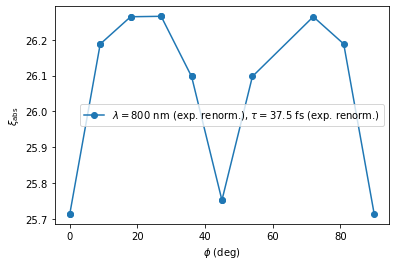

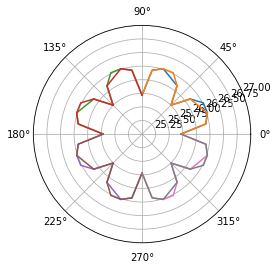

In [23]:
plt.figure()
plt.subplot(polar=False)
plt.plot(data3_6Vnm.PolarizationAngle*180./pi, data3_6Vnm.Energy_eV, "-o", label=r"$\lambda=800$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$\xi_{\mathrm{abs}}$")
plt.legend(loc="best")
plt.show()

plt.figure()
plt.subplot(polar=True)
plt.plot(data3_6Vnm.PolarizationAngle+0*45./180.*np.pi, data3_6Vnm.Energy_eV, "-", label=r"$\lambda=8$ nm (exp. renorm.), $\tau=$37.5 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data3_6Vnm.PolarizationAngle, data3_6Vnm.Energy_eV, "-")
plt.plot(data3_6Vnm.PolarizationAngle+2*45./180.*np.pi, data3_6Vnm.Energy_eV, "-")
plt.plot(4*45./180.*np.pi-data3_6Vnm.PolarizationAngle, data3_6Vnm.Energy_eV, "-")
plt.plot(data3_6Vnm.PolarizationAngle+4*45./180.*np.pi, data3_6Vnm.Energy_eV, "-")
plt.plot(6*45./180.*np.pi-data3_6Vnm.PolarizationAngle, data3_6Vnm.Energy_eV, "-")
plt.plot(data3_6Vnm.PolarizationAngle+6*45./180.*np.pi, data3_6Vnm.Energy_eV, "-")
plt.plot(8*45./180.*np.pi-data3_6Vnm.PolarizationAngle, data3_6Vnm.Energy_eV, "-")
plt.ylim([25,27])
plt.show()

Now that data is available, let's try to build up an angle-dependent plot, like in Tancogne-Dejean et al., Physical review letters, 2016, 118, 087403. 

In [24]:
"""import glob
for JobID_id in datatmp.JobID:
    print(("JobID: "+str(JobID_id)))
    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"
    # print(FileLookUp)
    ListFound = glob.glob("*/*/*/" + FileLookUp)
    # print(ListFound)
    entry=datatmp[datatmp.JobID==JobID_id]
    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double
    print(PolarizationAngle * 180. / np.pi)
    """

'import glob\nfor JobID_id in datatmp.JobID:\n    print(("JobID: "+str(JobID_id)))\n    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"\n    # print(FileLookUp)\n    ListFound = glob.glob("*/*/*/" + FileLookUp)\n    # print(ListFound)\n    entry=datatmp[datatmp.JobID==JobID_id]\n    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double\n    print(PolarizationAngle * 180. / np.pi)\n    '

In [25]:
!pwd

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Estimation of Brillouin zone boundary

In [26]:
from scipy.constants import hbar, h, c, e, epsilon_0, pi
import numpy as np

In [27]:
omega=2*pi*c/800e-9
intensity_log=np.linspace(10,np.log10(0.5E18),100)
intensity=np.power(10.,intensity_log)
intensity_Wcm2=intensity*1E-4
vector_potential=1./omega*np.sqrt(2*intensity/c/epsilon_0)
light_momentum=e/hbar*vector_potential
interatomic_distance=5.431e-10
Brillouin_zone_X=2*pi/interatomic_distance
Brillouin_zone_K=3*pi/(2*interatomic_distance)*2**0.5/2.

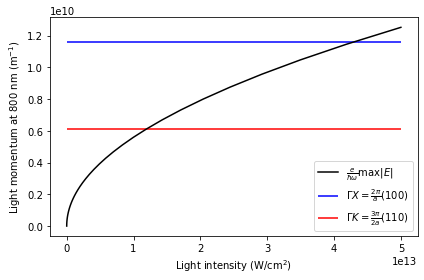

In [28]:
plt.figure()
plt.plot(intensity_Wcm2, light_momentum, "-k", label=r"$\frac{e}{\hbar \omega} \max \left|E\right| $")
plt.hlines(y=Brillouin_zone_X, color="b", xmin=np.min(intensity_Wcm2), xmax=np.max(intensity_Wcm2), label=r"$\Gamma X=\frac{2 \pi}{a}(100)$")
plt.hlines(y=Brillouin_zone_K, color="r", xmin=np.min(intensity_Wcm2), xmax=np.max(intensity_Wcm2), label=r"$\Gamma K=\frac{3 \pi}{2 a}(110)$")
plt.xlabel(r"Light intensity (W/cm$^{2}$)")
plt.ylabel("Light momentum at 800 nm (m$^{-1}$)")
plt.legend(loc=4)
plt.tight_layout()
plt.show()